# WAD2 G8T7: Training the HDB Resale Price Model

This Jupyter Notebook is a complete process workflow of how our group trained the price model used in our HDB Resale Finder app.

**What it does:** The model is trained to learn how much each feature of a flat (factors) affects its resale price, using multiple linear regression (compare how several independent variables would affect a single dependent variable) on log(price). The learned weights are saved for the app to use. 

One pooled model is trained on all sales in the 4 towns (AMK, Bishan, Punggol, Tampines), with town and flat type as features, so the effect of lease, size and storey is measured fairly across all towns.

**Why Offline (not live in the app)?** HDB's data only changes monthly, so the model is trained once per month here. The app just reads the saved weights and estimates prices instantly.

**Input:** `raw/resale-prices.csv`, HDB "Resale flat prices based on registration date from
Jan-2017 onwards" (data.gov.sg), downloaded on 27 Oct 2026.

**Output:** `../server/data/priceModel.json`, the model's weights, read by the app.

**How to rerun (each month when HDB publishes new data):**
1. Download the latest CSV from data.gov.sg into `prep/raw/resale-prices.csv`
2. Select the `hdb-price` kernel (pandas, scikit-learn, matplotlib, ipykernel)
3. Restart the kernel and Run All
4. Check $R^2$ and MAE in Step 6, then commit the new `priceModel.json`

**Steps:**
1. Load & Filter the data
2. Choose & Build the features
3. Take log(price)
4. Split into training and test sets
5. Fit the regression
6. Check the accuracy ($R^2$, average error in dollars)
7. Read the weights: lease decay, town premiums and price trend
8. Export the weights for the app


## Step 0. Setup (one time, in a terminal at project root folder)

This notebook runs in its own conda environment so its packages do not clash with other projects.

We need to understand Anaconda, which bundles 3 things: 

1. Python
2. Conda, the tool which creates and switches the environments and also install packages.
3. Hundreds of pre-installed packages such as (pandas, numpy, matplotlib, Jupyter, etc)

Mainly, we need conda from Anaconda to be able to manage Python environments.

```bash 
conda create -n hdb-price python=3.12 -y 
```
**create:** create a new environment<br>
**-n hdb-price:** name is hdb-price<br>
**python=3.12:** python version<br>
**-y:** answer yes automatically when conda asks to proceed<br>
So, you are creating a new empty environment for this project.

```bash
conda activate hdb-price
```
It switches to that environment.
```
Original: (base) user-laptop
```
```
After: (hdb-price) user-laptop
```

```bash
pip install pandas scikit-learn matplotlib ipykernel
```

Install the various libraries needed into the active env (hdb-price). Hence why you activate the env before installing. 



In [1]:
import sys, pandas, sklearn
print(sys.executable) #show where the Python that's running this notebook is located
print(pandas.__version__, sklearn.__version__) #versions of pandas and sklearn

/Users/shaun/anaconda3/envs/hdb-price/bin/python
3.1.0 1.9.1


### Libraries used:

pandas, numpy, matplotlib

We need to import them.

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

## Step 1a. Download and load the dataset

First, go to data.gov.sg and search 'resale hdb flat prices'. 

Next, download the dataset named: "Resale flat prices based on registration date from Jan-2017 onwards". 

Thirdly, rename the file as `resale-prices.csv` and put the file in `prep/raw/`. The file location should now be `prep/raw/resale-prices.csv`.

The date the dataset was downloaded for this notebook: 27 Oct 2026.

Now we need to import the pandas library so this notebook can use it.

We shall give it a short nickname 'pd', so it will be easier to write.


In [3]:
#using pandas here

df = pd.read_csv("raw/resale-prices.csv")
print(df.shape)
print(df.dtypes)
df.head()

(243611, 11)
month                      str
town                       str
flat_type                  str
block                      str
street_name                str
storey_range               str
floor_area_sqm         float64
flat_model                 str
lease_commence_date      int64
remaining_lease            str
resale_price           float64
dtype: object


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.0,Improved,1979,61 years 04 months,232000.0
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.0,New Generation,1978,60 years 07 months,250000.0
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,262000.0
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.0,New Generation,1980,62 years 01 month,265000.0
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,265000.0


What each line does:

```
df = pd.read_csv("raw/resale-prices.csv")
```

This line opens the CSV file and turns it into a **DataFrame**, pandas's table object, with rows and columns like a spreadsheet. We use the path relative to the file, hence raw/ and not prep/raw/. It then stores the table in a variable named 'df' (short for DataFrame), which every later step uses.

```
print(df.shape)
```
This prints the table's size as rows and columns

```
print(df.dtypes)
```
This prints the data type of each column and tells us which column's values are numbers. We should see 3 kinds:
1. int64: whole number - lease_commence_date
2. float64: decimal number - floor_area_sqm, resale_price
3. object(or str): text - month, town, flat_type, block, street_name, storey_range, flat_model, remaining_lease

This matters because regression only works with numbers. Hence, we must convert each value into numbers. 

```
df.head()
```
This prints the first 5 rows so we can just see the what a subset of the data looks like. 



## Step 1b. Filter the data to keep only the 4 towns we want

By running the code above, we can see that from `df.shape` and `df.head()`, the dataset has 243,611 sales. However, our app only aims to cover 4 towns, which are: AMK, Bishan, Punggol and Tampines. So, our model should only be trained using sales data in those towns. Otherwise, it would learn price patterns from towns the app never shows and thus be inaccurate.

**How we are going filter:** Make a True/False mask for every row by using `.isin()` to check whether the town is in our list of 4 towns. Then use `df[mask]` to keep only the rows marked True. 

**Simple Check:** Ensure all rows the 'town' column lists towns in the 4 towns list only.

In [4]:
TOWNS = ["ANG MO KIO", "BISHAN", "PUNGGOL", "TAMPINES"]

in_list_towns = df["town"].isin(TOWNS)

df = df[in_list_towns]

print(df.shape)
df["town"].value_counts()


(48634, 11)


town
PUNGGOL       17611
TAMPINES      16954
ANG MO KIO     9807
BISHAN         4262
Name: count, dtype: int64

It should print out 48634 and list out exactly the number of sales per town. 

### How have HDB resale prices changed over time in our 4 towns?

Before choosing which years to train our model on, we need to check how prices have moved over time. 

The year is the first 4 characters of "month", e.g. "2022-01"
We want to extract this:
```
df["year"] = df["month"].str[:4]
```

For each year, we need to find how many sales and the median price:

```
by_year = df.groupby("year")["resale_price"].agg(["count", "median"])
print(by_year)
```

**Why median?** We use the median not the mean because prices are right-skewed.

In [5]:
df["year"] = df["month"].str[:4]

by_year = df.groupby("year")["resale_price"].agg(["count", "median"]) #.agg is short for aggregate, which just means combine many values into one summary number
by_year["change_%"] = (by_year["median"].pct_change() * 100).round(1) #pct_change compares each year's median with the year before; turns it into a percentage and 1 dp
print(by_year)

      count    median  change_%
year                           
2017   4003  445888.0       NaN
2018   4324  443500.0      -0.5
2019   3944  440000.0      -0.8
2020   4893  455000.0       3.4
2021   6516  500000.0       9.9
2022   5200  548000.0       9.6
2023   5143  580888.0       6.0
2024   5430  635000.0       9.3
2025   4806  670000.0       5.5
2026   4375  688888.0       2.8


### Creating a chart displaying the median price per year

The above table after running the code is hard to read as a trend, so we plot the median price for each year as a line chart.

This makes it easier to see whether prices stayed flat, rose steadily, or changed direction, which decides which years to train the model on. 

We will use matplotlib to draw the chart:
- `plt.plot(x,y, marker="o")`: draws a line through the points, with a dot for each year
- `plt.title`, `plt.xlabel`, `plt.ylabel`: label the chart and both axes, x and y
- `plt.show()`: displays the chart below the cell

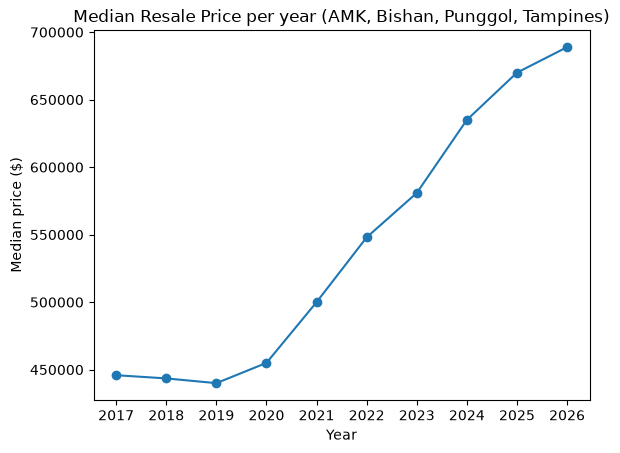

In [6]:
#using matplotlib.pyplot library here

plt.plot(by_year.index, by_year["median"], marker="o")
plt.title("Median Resale Price per year (AMK, Bishan, Punggol, Tampines)")
plt.xlabel("Year")
plt.ylabel("Median price ($)")
plt.show()

From this chart, we can see the median resale flat prices of the 4 towns is flat from 2017 to 2020 at around \$455k, and rising steadily from 2021 (\$500k) to 2026 (\$689k).

As such, we can see prices behave differently in the two time periods, the next chart shows exactly where the change happens.

### Chart: Yearly % Change in Median Price

The line chart only shows the overall shape, but to choose an exact start year, we need to see how fast prices changed each year. The bar chart below shows each year's % change from the year before. Years before our chosen start year are grey; years we train on are blue.

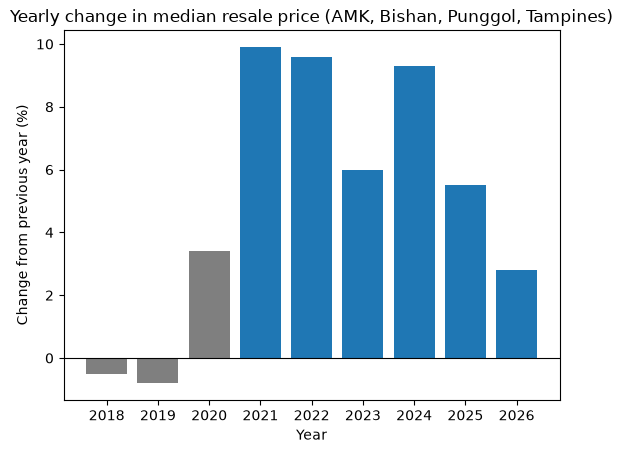

In [7]:
import matplotlib.pyplot as plt

#Drop 2017 as it has no previous year so no % change
changes = by_year["change_%"].dropna()

#Colour each bar: grey before our start year, blue from it onwards
START_YEAR = "2021"
colours = []
for year in changes.index:
    if year >= START_YEAR:
        colours.append("tab:blue")
    else:
        colours.append("tab:grey")

plt.bar(changes.index, changes, color=colours)
plt.axhline(0, color="black", linewidth=0.8) #line at 0% so ups and downs are clear
plt.title("Yearly change in median resale price (AMK, Bishan, Punggol, Tampines)")
plt.xlabel("Year")
plt.ylabel("Change from previous year (%)")
plt.show()

**What the chart shows:** From 2018 to 2020 (grey), prices barely changed.<br>
From 2021, prices rose every year by about 5-10%.

**So we train from 2021:** It is the 1st year of the steady rise. Starting earlier would mix in the flat period; starting later (2022) would drop 2021, which rose at a similar pace.

## Step 1c. Keep only recent sales (from 2021 onwards)

In [8]:
START_MONTH = "2021-01"

#True/False for every row to check if this sale is on or after START_MONTH
is_recent = df["month"] >= START_MONTH

#Keep only the rows which return true
df = df[is_recent]

#Check
print(df.shape)
print(df["month"].min(), df["month"].max())

(31470, 12)
2021-01 2026-10


## Step 1d. Final Checks before building features

Before turning columns into numbrs, we check three things:

1. **Missing Values**: Rows with empty cells would break the regression.
2. **Flat Types**: Flat Types with very few sales can't be learned reliably.
3. **Prices**: The range should look like real HDB prices, with no obvious errors.

In [9]:
#1. Missing values per column (should be all 0)
print(df.isna().sum())

#2. Number of sales per flat type
print(df["flat_type"].value_counts())

#3. Summary of prices: Count, Mean, Spread, Min, Quartiles, Max
df["resale_price"].describe()


month                  0
town                   0
flat_type              0
block                  0
street_name            0
storey_range           0
floor_area_sqm         0
flat_model             0
lease_commence_date    0
remaining_lease        0
resale_price           0
year                   0
dtype: int64
flat_type
4 ROOM              13817
5 ROOM               8327
3 ROOM               7080
EXECUTIVE            1584
2 ROOM                635
MULTI-GENERATION       27
Name: count, dtype: int64


count    3.147000e+04
mean     6.140635e+05
std      1.832629e+05
min      1.500000e+05
25%      4.800000e+05
50%      5.950000e+05
75%      7.200000e+05
max      1.711000e+06
Name: resale_price, dtype: float64

### Based on the output, we can interpret that:

1. Missing Values are all 0. As such, there are no missing values and nothing to remove. 

2. For flat types, we can see that MULTI-GENERATION has very few sales. The model is unable to learn a reliable weight from that few sales, so we remove it. 

3. For prices, most sales are between \$480k (25%) and \$720k (75%), with a median of \$595k. Since the mean (\$614k) is above the median (\$595k), this shows the data is skewed to the right, which we fix with log(price).



In [10]:
#Drop MULTI_GENERATION (27 sales, and none of our app's blocks are multi-generation)
df = df[df["flat_type"] != "MULTI-GENERATION"]

#The year column is dropped, only needed for the chart above because the next step (the model's time feature) is built from `month` instead
df = df.drop(columns="year")

print(df.shape)


(31443, 11)


**Step 1d Summary:** 31,443 sales in AMK, Bishan, Punggol, Tampines from Jan-2021 to Oct-2026 of 5 flat types with no missing values.

**Why log(price):** For this project, we conducted multiple linear regression on log(price). The reason being that each weight becomes a percentage effect. 

Compare these two flats: 
- a 2-room in AMK at $232000 (Jan 2017, row 1 from raw)
- a 5-room in Bishan at $830000 (Jan 2017, row 147 from raw)

Supposed being 10 floors higher is worth about 5%. That is $11600 for the cheaper 2-room flat in AMK vs $41500 for the 5-room flat in Bishan. On raw prices, the model can only learn one fixed dollar amount for '10 floors higher' for every flat. Essentially, it is too much for the cheaper flat ($232k) and too little for the expensive flat ($830k) to move up higher. 

By conducting the linear regression on log(price):
Each weight becomes a percentage effect, so "+5%" applies naturally to both. 

**Skewed HDB Prices:** Additionally, HDB prices are skewed, with most of them being between $400k - $900k, but there is a long tail to the right that stretches all the way till $1.7M. This means the graph is lopsided and is skewed right (positively skewed).
The few very expensive flats pull the average (mean) up. 
**Note: This is only for the 4 towns in the last 12 months.**

**How Log(price) solves the issue of Skewed HDB Prices:** Log measures by ratio, not by difference. Eg. $300k -> $600k and $600k -> $1.2M are both a gap of 0.69 in log because both are doubling.

Log turns "times 2" into "plus the same amount".
This balances the lopsided shape. 

**What are Residuals:** For every sale in the data, the model makes a guess, and we compare it with the real price: 
error = real price - predicted price

Example: a flat really sold for $650k but the model guessed $620k, so the error is +$30k (the model guessed too low.) 

**How does the model choose its weights?:** Linear Regression calculates the set of weights where: 
(error₁)² + (error₂)² + (error₃)² + …   is as **SMALL** as possible
**This is called least squares.**
**Why square?**
* So negative and positive errors don't cancel out. 
* To punish big mistakes more: being $60k off counts 4x as much as $30k off, not 2x.

## Step 2. Building the features

Linear Regression can only learn from **numbers**, and not text. It predicts the price by multiplying each feature by a weight and adding them up. (e.g. 0.005 x storey). So, we need to turn each column we want to use into a number (a feature) that the model can learn from.

## Step 2a. Storey

Higher floors usually sell for more: better views, more breeze, less noise from the street. So the floor is a factor the model should learn. E.g. "each extra floor adds about X% to the price."

From the data, we can see that HDB only records a 3-floor band from the column **storey_range**, not the exact floor. The model needs one number per flat, so we use the middle floor as the best single estimate as it is never more than 1 floor away from the real floor. 

So we split the floor band at " TO " and turn both numbers into integers and take their average. 


In [11]:
#2a. Storey: "10 TO 12" -> 11 (middle floor of the band)

#Split each band into 2
storey_parts = df["storey_range"].str.split(" TO ") #working on a whole column so u need .str

#First piece = lowest floor, second = highest; turn both into whole numbers
low = storey_parts.str[0].astype(int)
high = storey_parts.str[1].astype(int)

df["storey"] = (low + high) / 2

#Check text band next to the new number
df[["storey_range", "storey"]].head(10)


,storey_range,storey
87589,01 TO 03,2.0
87590,07 TO 09,8.0
87591,04 TO 06,5.0
87592,04 TO 06,5.0
87593,01 TO 03,2.0
87594,07 TO 09,8.0
87595,04 TO 06,5.0
87596,04 TO 06,5.0
87597,07 TO 09,8.0
87598,04 TO 06,5.0


In [12]:
#count how many sales there are on each floor, and list the floors from lowest to highest
df["storey"].value_counts().sort_index()

storey
2.0     5289
5.0     7419
8.0     6982
11.0    6010
14.0    3187
17.0    1728
20.0     337
23.0     224
26.0     118
29.0      92
32.0      36
35.0      13
38.0       6
41.0       2
Name: count, dtype: int64

**Result:** Each Storey Band is now 1 number in the new column `storey` (e.g. "01 TO 03" -> 2)

- There are 14 different storeys, from floor 2 to 41, all 3 apart, with no odd values.
- Most sales are from floor 2 to 11 (5289 + 7419 + 6982 + 6010)/ 31,443 = 0.817 (~82%), floors 14 to 17 is (3187 + 1728) / 31,443 = 0.156 (~16%), floor 20 and above is the remaining 3%. Hence, the storey effect is most reliable for low and middle floors.

## Step 2b. Remaining Lease: years left at the time of sale

HDB flats have a 99-year lease. The less lease is left, the less a flat is worth (fewer years left for the buyer, and banks lend less on short leases). This is called **Lease Decay**, so the model needs the years of lease left when each flat is sold. From this feature, the model learns how much the price changes for each extra year of lease left, holding the other features fixed.

**Why calculate it ourselves instead of just using the `remaining_lease` column?** This is because `remaining_lease` text is not consistent (E.g. 61 years and 62 years 08 months), and our app only knows each block's **Lease Start Year**. Hence, we calculate it the same way the app can:

```
lease left = 99 - (time of sale - year the lease started)
```

In [13]:
#2b. Remaining lease at the time of sales, in years

#We need to extract the sale year and month e.g. "2023-08"
sale_year = df["month"].str[:4].astype(int)
sale_month = df["month"].str[5:].astype(int)

#Time of sale as a decimal year, e.g. Aug 2023 -> 2023 + 7/12 = 2023.58, sale_month - 1 because you count it as months that already passes, so for e.g January counts as 0 months not 1
sale_time = sale_year + (sale_month - 1) / 12

df["lease_years"] = 99 - (sale_time - df["lease_commence_date"])

#Check the number next to HDB's text for a few rows
df[["month", "lease_commence_date", "remaining_lease", "lease_years"]].head(10)


,month,lease_commence_date,remaining_lease,lease_years
87589,2021-01,1986,64 years 01 month,64.0
87590,2021-01,1986,64 years 01 month,64.0
87591,2021-01,1981,59 years,59.0
87592,2021-01,1980,58 years 02 months,58.0
87593,2021-01,1980,58 years 01 month,58.0
87594,2021-01,1986,64 years 02 months,64.0
87595,2021-01,1980,58 years 02 months,58.0
87596,2021-01,1981,59 years 01 month,59.0
87597,2021-01,1986,64 years,64.0
87598,2021-01,1976,54 years 04 months,54.0


In [14]:
#Summary of lease years left across all sales, rounded to 1 d.p.
df["lease_years"].describe().round(1)

count    31443.0
mean        75.2
std         15.0
min         45.2
25%         60.8
50%         75.7
75%         90.8
max         95.3
Name: lease_years, dtype: float64

**Result:** There is a new column `lease_years`, the years of lease left at the time of each sale. 

Based on the results, we can see that the lease left ranges from 45.2 to 95.3 years, with a median of 75.7 years.

The spread is wide as a quarter of sales have under 60.8 years left and a quarter have over 90.8 years. This wide range is what lets the model measure lease decay. 

## Step 2c. Time: months since Jan 2021

Prices rose steadily over our training period (Step 1). Without a time feature, the model is unable to tell a 2021 sale from a 2026 sale and would wrongly credit the price rise is to other features. Hence, we need to count each sale's month so the model is able to learn from the data and predict how much prices change per month, providing a predicted price trend. 

months since start = (sale year - 2021) x 12 + (sale month - 1) 

In [15]:
#2c. Time: months since START_MONTH (Jan 2021), e.g. for 2023-08, it will be 31 months since Jan 2021

# The first year of our data, taken from START_MONTH so the 2 always match
start_year = int(START_MONTH[:4])

#Years since the start (in months) + months into that year
df["months_since_start"] = (sale_year - start_year) * 12 + (sale_month - 1)

#Check each month once, next to its number
df[["month", "months_since_start"]].drop_duplicates().head(10)

,month,months_since_start
87589,2021-01,0
90080,2021-02,1
92240,2021-03,2
94683,2021-04,3
97016,2021-05,4
98973,2021-06,5
101275,2021-07,6
103934,2021-08,7
106673,2021-09,8
109189,2021-10,9


In [16]:
#range check
print(df["months_since_start"].min(), df["months_since_start"].max())

0 69


**Result:** The new column `months_since_start` shows the number of months since Jan 2021 for each sale. 

It runs from 0 (Jan 2021) to 69 (Oct 2026), going up by 1 each month (e.g. Feb 2021 -> 1)

This lets the model learn the price trend as a % change per month, which we can later turn into \$ per year. 

## Step 2d. Floor area: log(area)

Bigger flats cost more, so floor area is a key feature. We use **log(area)** instead of raw sqm because size matters in proportion: Going from 50 to 60 sqm (+20%) is a much bigger change than 130 to 140 sqm (+8%). With log(area), the weight means "% change in price for a 1% bigger flat", which is the same for flats of all sizes.

This also means our lease effect can be read as the effect on **price per sqm**.

In [17]:
#2d. Floor area: log of the floor area in sqm
#using numpy here

df["log_area"] = np.log(df["floor_area_sqm"])

#check area next to its log
df[["floor_area_sqm", "log_area"]].head(10)

,floor_area_sqm,log_area
87589,45.0,3.806662
87590,45.0,3.806662
87591,68.0,4.219508
87592,68.0,4.219508
87593,68.0,4.219508
87594,60.0,4.094345
87595,68.0,4.219508
87596,68.0,4.219508
87597,60.0,4.094345
87598,73.0,4.290459


In [18]:
#Range check: floor area and its log
df[["floor_area_sqm", "log_area"]].describe().round(2)

,floor_area_sqm,log_area
count,31443.00,31443.00
mean,96.90,4.55
std,22.07,0.24
min,37.00,3.61
25%,84.00,4.43
50%,93.00,4.53
75%,112.00,4.72
max,243.00,5.49


**Result:** This creates a new column `log_area`, which is the log of the floor area. 

**Interpretation of data:** Floor area ranges from 37 to 243 sqm, and the median is 93 sqm, so `log_area` ranges from 3.61 to 5.49. <br>
As you can see from the data, the largest flat is about 6.57x the smallest, but its log is only about 1.5x bigger. That is the "in proportion" effect we want, the log squeezing the range.

## Step 2e. Town and Flat Type

We know that location of a HDB flat and the flat type affects the price. Bishan is a pricier location compared to Punggol, and a 5-room costs more than a 3-room. The model needs this information as numbers, but currently they're categories (names), not amounts.

### How do we turn a name into numbers?

If we were to number them (AMK=1, Bishan=2, Punggol=3, Tampines=4) it would treat the towns as amounts which is meaningless, because towns have no order. <br>
Instead, we do one-hot encoding, which is one 0/1 column per category. Each town gets its own on/off switch, and its switch gets its own weight e.g. "being in Bishan adds +X% to the price".

Instead of having all 4 town columns, we use AMK as the **baseline.**

**Why is that?** 
- This is because it isn't needed. If all 3 switches are 0, the flat must be in AMK and a 4th column would add no new information.
- It would break the model because the 4 columns always add up to 1 for every row, which exactly copies the model's starting value (the intercept). The model then can't tell them apart, and the weights become unstable. This is called the **dummy variable trap**.

**What the baseline means for reading the weights:** Every town weight is compared with AMK. `town_BISHAN` = +0.15 means a Bishan flat costs about 15% more than an otherwise identical AMK flat. The same goes for flat type: the baseline is 2 ROOM, so `flat_type_5 ROOM` is compared with a 2 ROOM of the same size and lease.

In [19]:
#2e. Town and flat type -> converted to 0/1 columns with the 1st category left out as the baseline
df = pd.get_dummies(df, columns=["town", "flat_type"], drop_first=True, dtype=int) #we want to drop the 1st category, so drop_first=True

#check the new 0/1 columns
new_columns = [col for col in df.columns if col.startswith("town_") or col.startswith("flat_type_")]
print(new_columns)
df[new_columns].head()


['town_BISHAN', 'town_PUNGGOL', 'town_TAMPINES', 'flat_type_3 ROOM', 'flat_type_4 ROOM', 'flat_type_5 ROOM', 'flat_type_EXECUTIVE']


,town_BISHAN,town_PUNGGOL,town_TAMPINES,flat_type_3 ROOM,flat_type_4 ROOM,flat_type_5 ROOM,flat_type_EXECUTIVE
87589,0,0,0,0,0,0,0
87590,0,0,0,0,0,0,0
87591,0,0,0,1,0,0,0
87592,0,0,0,1,0,0,0
87593,0,0,0,1,0,0,0


**Result:** `town` and `flat_type` are replaced by 7 0/1 columns: 3 for towns and 4 for flat types.

AMK and 2 ROOM are the baselines (no column), so their effect is built into the starting value and every other town and flat type is measured against them.